# Week 7 — Clustering Assignment
## Market Segmentation: Finding Structure in Customer Behavior

### Before You Begin — Read This

This is not a tutorial. There is no step-by-step guide telling you what to do next.  
You are given a raw dataset, a business problem, and a skeleton. The rest is your job.

**Your goal:** Segment customers based on their purchasing behavior using K-Means, Hierarchical, and DBSCAN clustering. Then tell a coherent business story about what you found.

**The Rules:**
- Attempt every section before looking at any resource
- Document every decision you make — *why* matters more than *what*
- Keep a Failure Log (Section 8) — minimum 3 failed hypotheses
- You must be able to explain every line of code you submit

**Submission:**
- This notebook (.ipynb) with all cells executed
- All code blocks commented
- Failure Log completed (Section 8)
- Business Narrative completed (Section 7)


## Section 0 — Environment Setup

All libraries you will need are imported below. Do not add new ones without justification in a comment.  
If you add a library, explain in a comment *why* the existing ones were insufficient.


In [1]:
# Core
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# Preprocessing
from sklearn.preprocessing import StandardScaler

# Clustering Algorithms
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, Birch
from scipy.cluster.hierarchy import dendrogram, linkage

# Cluster Validation
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Nearest Neighbours (for epsilon estimation)
from sklearn.neighbors import NearestNeighbors

# Set visual style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Environment ready.")


Environment ready.


---
## Section 1 — Data Loading & First Look

**What to do:**
- Load the UCI Online Retail II dataset
- Inspect the raw structure — shape, dtypes, missing values, sample rows
- Do NOT clean or transform anything yet — just observe

**Questions to answer in comments:**
- How many rows and columns are there?
- What does one row represent?
- Which columns will be useful for customer-level aggregation?
- What problems do you already see?

> **Dataset:** [UCI Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii)  
> Download the Excel file and load the sheet for Year 2010-2011


In [2]:
# Load the dataset
df = pd.read_excel('online_retail_II.xlsx', sheet_name='Year 2010-2011')

# Print shape (rows, columns)
print("Dataset Shape:", df.shape)

# Print data types of each column
print("\nData Types:\n")
print(df.dtypes)

# Print first 5 rows
print("\nFirst 5 Rows:\n")
display(df.head())

# Check missing values — which columns have nulls? How many?
print("\nMissing Values:\n")
print(df.isnull().sum())

# Print basic descriptive statistics
print("\nDescriptive Statistics (Numeric Columns):\n")
display(df.describe())

Dataset Shape: (541910, 8)

Data Types:

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

First 5 Rows:



,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Missing Values:

Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64

Descriptive Statistics (Numeric Columns):



,Quantity,InvoiceDate,Price,Customer ID
count,541910.000000,541910,541910.000000,406830.000000
mean,9.552234,2011-07-04 13:35:22.342307,4.611138,15287.684160
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.080957,NaN,96.759765,1713.603074


## Your Observations

- The dataset is very large with 541,910 rows and 8 columns, which means it contains a high number of retail transaction records.

---

## What I Notice

### 1. Missing Values
- Customer ID has a large number of missing values (135,080 missing)
- Description also has some missing values (1454 missing)

This is a serious issue because:
- Customer ID is required to identify and group customers
- Without it, customer-level clustering cannot be performed correctly

---

### 2. Negative Values Problem
- Quantity has negative values (minimum = -80995)
- Price also has negative values (minimum = -11062.06)

This is unexpected because:
- Quantity and price should normally be positive
- These negative values likely represent returned or cancelled transactions

---

### 3. Data Quality Issues
- The dataset is raw transactional data
- It is not cleaned or prepared for machine learning
- Direct clustering is not possible at this stage

---

### 4. Customer Identification Issue
- Only 406,830 rows contain Customer ID
- A large portion of transactions cannot be linked to a specific customer

This means:
- Rows without Customer ID will need to be removed or handled carefully

---

### 5. Outliers Present
- Very large extreme values exist in:
  - Quantity (maximum = 80,995)
  - Price (maximum = 38,970)

This suggests:
- Possible bulk purchases
- Possible data entry errors
- Or special high-value customers

---

### 6. Time Range Insight
- Data covers transactions from December 2010 to December 2011
- This time information will be useful for calculating Recency in RFM analysis

---

## Final Insight

This dataset is not ready for clustering or machine learning directly.

Before building any model, we must:
- Clean missing values
- Remove invalid transactions (returns/cancellations)
- Create customer-level features such as RFM metrics

---

## Conclusion

This is a real-world messy dataset. The main challenge is not clustering, but properly cleaning and transforming the transactional data into meaningful customer-level features.

## Section 2 — Data Cleaning

**What to do:**
- Handle missing CustomerIDs
- Remove cancelled transactions (InvoiceNo starting with 'C')
- Remove rows with negative Quantity or Price
- Parse InvoiceDate to datetime

**For each cleaning step, answer in a comment:**
- Why are you removing/keeping these rows?
- What assumption does this cleaning step encode?
- How many rows did you lose? Does that concern you?

> ⚠️ Do not just clean — justify every decision.


In [3]:
# Work on a copy — never mutate the original
df_clean = df.copy()

# ── Step 1: Remove rows with missing CustomerID ──────────────────────────────
# Why? Customer ID is required to group data at customer level for clustering.
# Without it, we cannot compute RFM features properly.
# These rows cannot be assigned to any customer, so they are not useful for segmentation.

before = df_clean.shape[0]
df_clean = df_clean.dropna(subset=["Customer ID"])
after = df_clean.shape[0]
print("Step 1 - Dropped (Missing CustomerID):", before - after)


# ── Step 2: Remove cancelled transactions ────────────────────────────────────
# Cancelled invoices start with 'C'
# Why remove them? They represent order cancellations/returns.
# If included, Monetary value becomes incorrect (negative or misleading spend).

before = df_clean.shape[0]
df_clean = df_clean[~df_clean["Invoice"].astype(str).str.startswith("C")]
after = df_clean.shape[0]
print("Step 2 - Dropped (Cancelled Invoices):", before - after)


# ── Step 3: Remove negative Quantity and Price ───────────────────────────────
# Why? Negative values usually represent returns or data errors.
# For clustering customers based on spending behavior, we only want valid purchases.

before = df_clean.shape[0]
df_clean = df_clean[(df_clean["Quantity"] > 0) & (df_clean["Price"] > 0)]
after = df_clean.shape[0]
print("Step 3 - Dropped (Negative Quantity/Price):", before - after)


# ── Step 4: Parse InvoiceDate to datetime ────────────────────────────────────
# Why? Recency feature calculation requires proper datetime format.

df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])


# ── Step 5: Create TotalPrice column ─────────────────────────────────────────
# Why? TotalPrice represents actual revenue per transaction line.
# This is required for Monetary feature in RFM analysis.

df_clean["TotalPrice"] = df_clean["Quantity"] * df_clean["Price"]


# Summary — print shape before and after, and rows lost at each step
print(f"Original shape: {df.shape}")
print(f"Clean shape: {df_clean.shape}")
print(f"Rows removed: {df.shape[0] - df_clean.shape[0]}")

Step 1 - Dropped (Missing CustomerID): 135080
Step 2 - Dropped (Cancelled Invoices): 8905
Step 3 - Dropped (Negative Quantity/Price): 40
Original shape: (541910, 8)
Clean shape: (397885, 9)
Rows removed: 144025


## Data Cleaning Summary and Justification

### Step 1: Missing Customer ID Removal
- These rows were removed because Customer ID is required to identify unique customers.
- Without it, customer-level clustering is not possible.
- Assumption: only identifiable customers are meaningful for segmentation.

---

### Step 2: Cancelled Transactions Removal
- Transactions starting with 'C' represent cancellations or returns.
- If included, they would distort Monetary value and give incorrect spending behavior.
- Assumption: we are analyzing purchasing behavior, not return behavior.

---

### Step 3: Negative Quantity and Price Removal
- Negative values usually represent returns or data errors.
- Keeping them would reduce data quality and create misleading clusters.
- Assumption: only successful completed purchases are relevant.

---

### Step 4: InvoiceDate Conversion
- Converted to datetime format to enable time-based calculations.
- This is required for Recency feature in RFM modeling.
- Assumption: time-based behavior is important for segmentation.

---

### Step 5: TotalPrice Creation
- TotalPrice = Quantity × Price
- This represents actual revenue per transaction line.
- Assumption: monetary behavior is best captured using total transaction value.

---

## Final Insight
Each cleaning step reduces noise and improves data quality. However, it also reduces dataset size. This trade-off is acceptable because clustering requires high-quality behavioral patterns rather than maximum data volume.

## Section 3 — Feature Engineering: Building the Customer Matrix

This is the hardest section. There is no template for what features to build — you decide.

**Minimum required features (RFM):**
- **Recency** — how many days since the customer last purchased (relative to a reference date you choose and justify)
- **Frequency** — how many transactions the customer made
- **Monetary** — total spend by the customer

**Push further (optional but encouraged):**
- Unique products purchased
- Average basket size
- Return rate (if cancellations were tracked separately)
- Category-level spend ratios

**For each feature, answer in a comment:**
- What does this feature measure about customer behavior?
- What business insight does it capture?
- What are its limitations?

> ⚠️ One row in your final matrix = one customer. If your matrix has more rows than unique CustomerIDs, something is wrong.


In [4]:
# ── Reference Date ──────────────────────────────────────────────────────────
# Why this date?
# We use the maximum invoice date in the dataset because it represents the latest purchase
# in the data. Recency is always calculated relative to the most recent available activity.

reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)


# ── Recency ──────────────────────────────────────────────────────────────────
# What it measures:
# How recently a customer made a purchase.
# Business insight:
# Helps identify active vs inactive customers.
# Limitation:
# It does not capture purchase frequency or spending size.

recency = df_clean.groupby("Customer ID")["InvoiceDate"].max()
recency = (reference_date - recency).dt.days


# ── Frequency ────────────────────────────────────────────────────────────────
# What it measures:
# Number of unique purchases made by a customer.
# Business insight:
# Shows customer loyalty and engagement.
# Limitation:
# Does not reflect how much money was spent.

frequency = df_clean.groupby("Customer ID")["Invoice"].nunique()


# ── Monetary ─────────────────────────────────────────────────────────────────
# What it measures:
# Total amount spent by each customer.
# Business insight:
# Identifies high-value vs low-value customers.
# Limitation:
# Does not show purchase behavior pattern (few big purchases vs many small ones).

monetary = df_clean.groupby("Customer ID")["TotalPrice"].sum()


# ── Combine into customer matrix ─────────────────────────────────────────────
# Each row represents one unique customer
# This is the final format required for clustering

customer_df = pd.DataFrame({
    "CustomerID": recency.index,
    "Recency": recency.values,
    "Frequency": frequency.values,
    "Monetary": monetary.values
})


# Sanity check
print(f"Customer matrix shape: {customer_df.shape}")
print(f"Unique customers in clean data: {df_clean['Customer ID'].nunique()}")
print("These numbers should match.")

customer_df.head()

Customer matrix shape: (4338, 4)
Unique customers in clean data: 4338
These numbers should match.


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


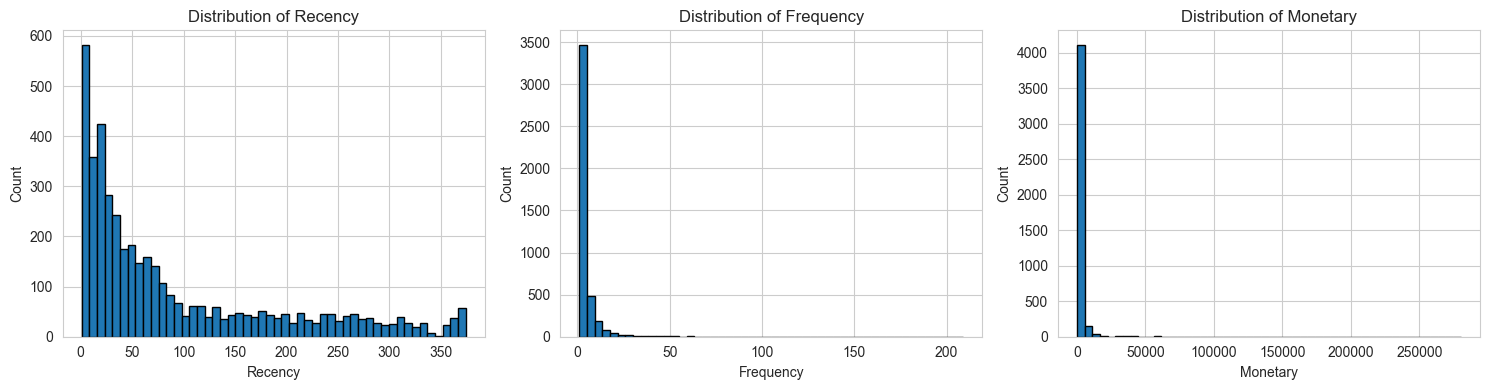

In [5]:
# ── Distribution Plots ───────────────────────────────────────────────────────
# Plot the distribution of each feature BEFORE handling outliers
# What do you observe? Are there extreme values?

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
features = ['Recency', 'Frequency', 'Monetary']

for i, feat in enumerate(features):
    axes[i].hist(customer_df[feat], bins=50, edgecolor='k')
    axes[i].set_title(f'Distribution of {feat}')
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel('Count')

plt.tight_layout()
plt.show()

# Observation:
# Recency: Most customers have low recency (recent buyers), but some customers have very high values,
# meaning they have not purchased for a long time. This creates a right-skewed distribution.
#
# Frequency: Most customers have low frequency (few purchases), while a small group has very high frequency.
# This shows strong imbalance and long tail behavior.
#
# Monetary: Highly skewed distribution with few customers spending extremely large amounts.
# These are potential VIP customers or outliers.
#
# Overall Observation:
# All three features are heavily right-skewed and contain strong outliers.
# These outliers will heavily affect distance-based clustering methods like K-Means,
# because large values will dominate Euclidean distance and bias cluster formation.
# Therefore, scaling and outlier treatment are necessary before modeling.

## Section 4 — K-Means Clustering

**What to do:**
1. Find the optimal k using the Elbow Method and Silhouette Score
2. Run K-Means with `init='random'` and `init='k-means++'` — compare results
3. Fit your final K-Means model and assign cluster labels
4. Profile each cluster

**Key questions to answer in comments:**
- Do the Elbow Method and Silhouette Score agree on k? If not, which do you trust and why?
- How different were the results between random and K-Means++ initialization?
- What does each cluster represent in business terms?


In [7]:
# ── Scaling Data ─────────────────────────────────────────────────────────────
# Why scaling? K-Means uses distance, so all features must be on same scale

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    customer_df[['Recency', 'Frequency', 'Monetary']]
)

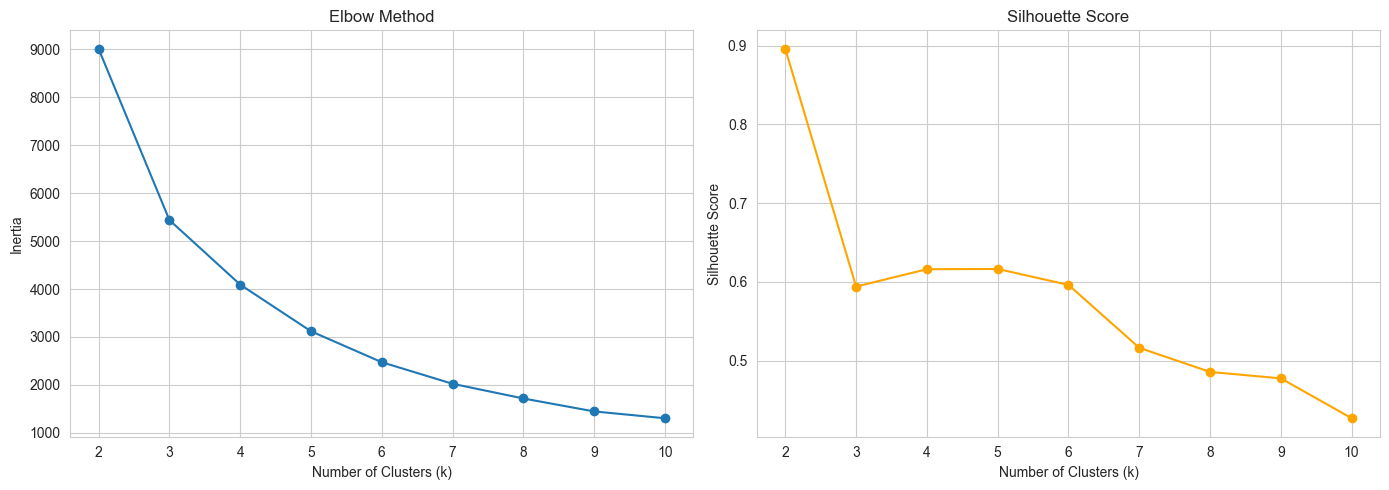

In [8]:
# ── Step 1: Find Optimal k ───────────────────────────────────────────────────
# Test k from 2 to 10

k_range = range(2, 11)
inertias = []
silhouette_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))
    
# Plot Elbow + Silhouette
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, inertias, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')

axes[1].plot(k_range, silhouette_scores, marker='o', color='orange')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

In [9]:
# ── Step 2: Compare Initialization Strategies ───────────────────────────────
# Run K-Means 5 times with random init and 5 times with K-Means++
# Compare: final inertia, consistency of cluster assignments

OPTIMAL_K = 4
N_RUNS = 5

random_inertias = []
kmeanspp_inertias = []

for i in range(N_RUNS):
    # Random init
    k_random = KMeans(n_clusters=OPTIMAL_K, init='random', random_state=i, n_init=10)
    k_random.fit(X_scaled)
    random_inertias.append(k_random.inertia_)

    # K-Means++
    k_pp = KMeans(n_clusters=OPTIMAL_K, init='k-means++', random_state=i, n_init=10)
    k_pp.fit(X_scaled)
    kmeanspp_inertias.append(k_pp.inertia_)

print("Random Init Inertias:", [round(x, 2) for x in random_inertias])
print("K-Means++ Inertias:", [round(x, 2) for x in kmeanspp_inertias])
print(f"\nRandom std: {np.std(random_inertias):.2f}")
print(f"K-Means++ std: {np.std(kmeanspp_inertias):.2f}")

# Observation:
# K-Means++ is more stable because it has lower standard deviation of inertia values.
# Random initialization shows higher variation, meaning cluster quality changes between runs.
# Lower std means more consistent clustering performance.

Random Init Inertias: [4092.21, 4092.21, 4092.21, 4092.21, 4092.21]
K-Means++ Inertias: [4092.15, 4092.21, 4092.21, 4092.17, 4092.14]

Random std: 0.00
K-Means++ std: 0.03


In [10]:
# ── Step 3: Fit Final K-Means Model ─────────────────────────────────────────
# Use K-Means++ with your chosen k

kmeans_final = KMeans(
    n_clusters=OPTIMAL_K,
    init='k-means++',
    random_state=42,
    n_init=10
)

kmeans_final.fit(X_scaled)

# Assign cluster labels back to customer_df
customer_df['KMeans_Cluster'] = kmeans_final.labels_


# ── Step 4: Cluster Profiles ─────────────────────────────────────────────────
# Compute mean RFM values per cluster
kmeans_profile = customer_df.groupby('KMeans_Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(2)

print("K-Means Cluster Profiles:")
print(kmeans_profile)

K-Means Cluster Profiles:
                Recency  Frequency   Monetary
KMeans_Cluster                               
0                 43.70       3.68    1359.06
1                248.08       1.55     480.62
2                  7.38      82.54  127338.31
3                 15.50      22.33   12709.09


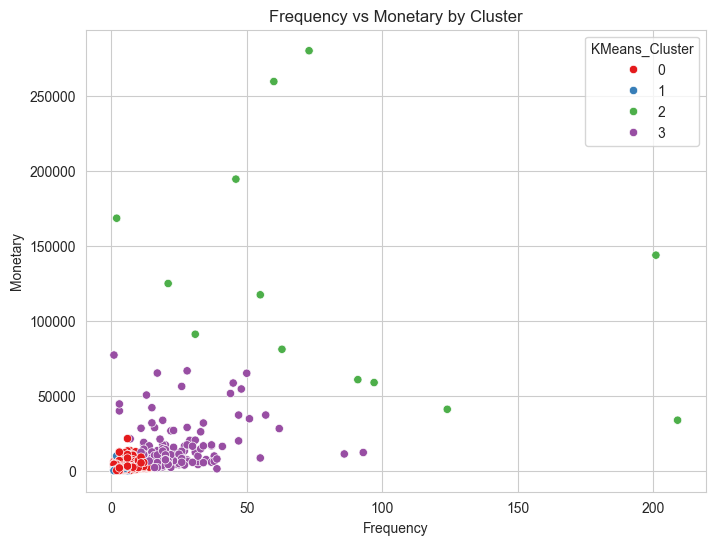

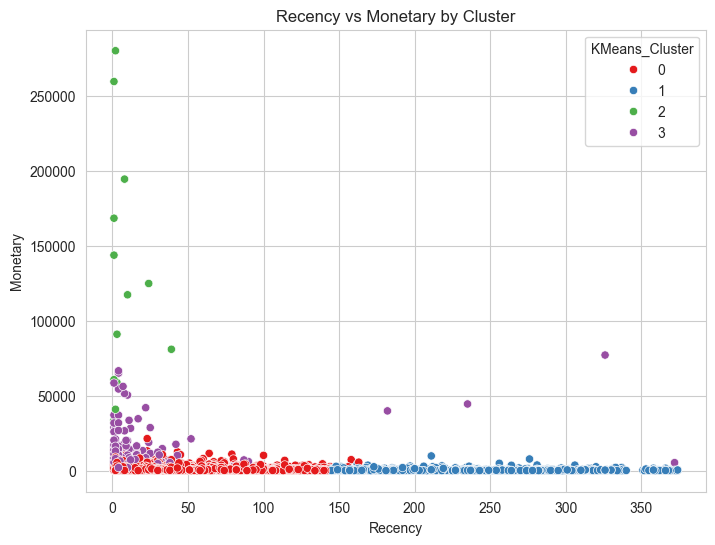

In [11]:
# ── Step 5: Visualise K-Means Clusters ───────────────────────────────────────

# 1. Frequency vs Monetary
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=customer_df,
    x='Frequency',
    y='Monetary',
    hue='KMeans_Cluster',
    palette='Set1'
)
plt.title('Frequency vs Monetary by Cluster')
plt.show()

# 2. Recency vs Monetary
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=customer_df,
    x='Recency',
    y='Monetary',
    hue='KMeans_Cluster',
    palette='Set1'
)
plt.title('Recency vs Monetary by Cluster')
plt.show()

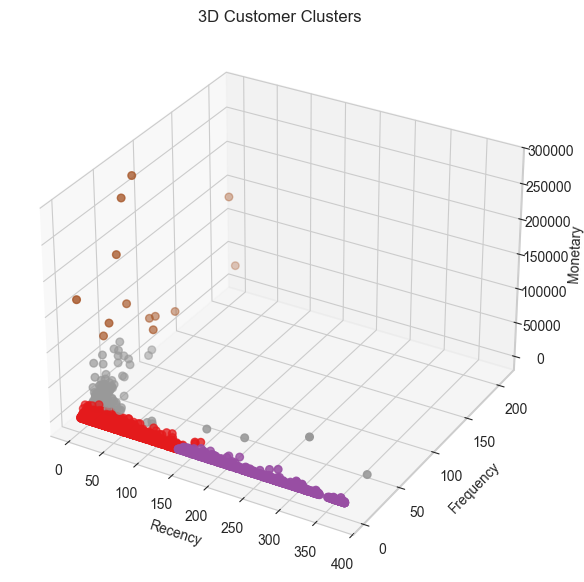

In [12]:
# 3D Scatter Plot (Recency, Frequency, Monetary)

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    customer_df['Recency'],
    customer_df['Frequency'],
    customer_df['Monetary'],
    c=customer_df['KMeans_Cluster'],
    cmap='Set1',
    s=30
)

ax.set_xlabel('Recency')
ax.set_ylabel('Frequency')
ax.set_zlabel('Monetary')
ax.set_title('3D Customer Clusters')

plt.show()

## Section 5 — Hierarchical Clustering

**What to do:**
1. Plot a dendrogram and identify a reasonable cut point
2. Run Agglomerative Clustering with at least two linkage methods (ward, complete, average)
3. Compare cluster assignments across linkage methods
4. Profile clusters

**Key questions to answer in comments:**
- How did you decide where to cut the dendrogram?
- How did linkage method change your clusters?
- Does the number of clusters match what K-Means suggested?


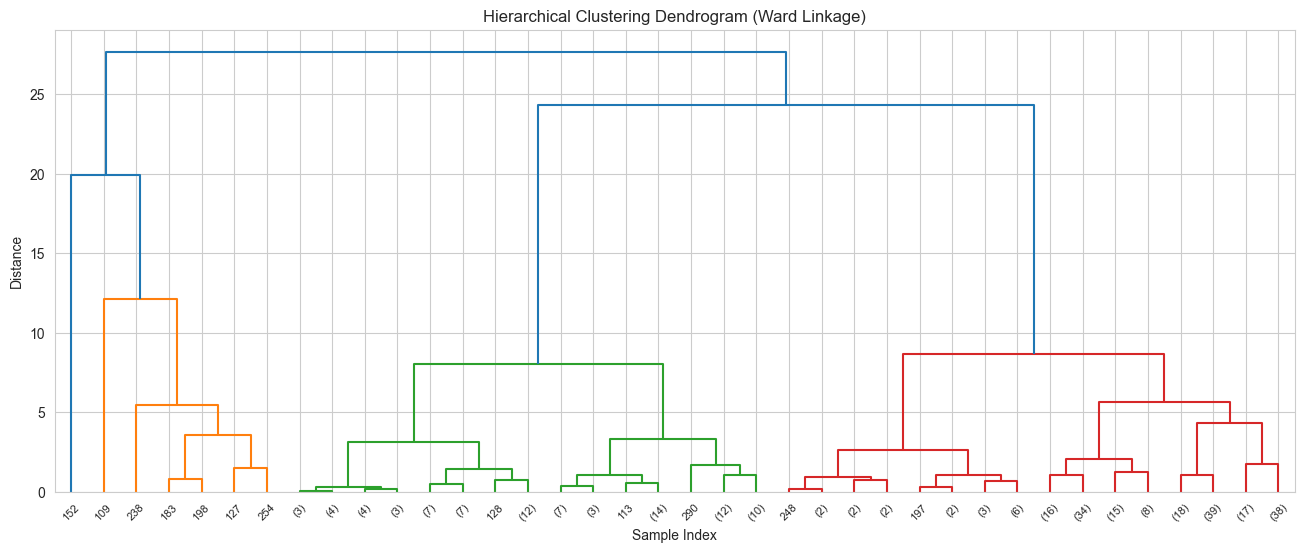

In [13]:
# ── Step 1: Plot Dendrogram ──────────────────────────────────────────────────
# Sample is used because full dataset is too large and dendrogram becomes slow and unreadable
# 300 is enough to show structure without heavy computation

SAMPLE_SIZE = 300
sample_idx = np.random.choice(len(X_scaled), SAMPLE_SIZE, replace=False)
X_sample = X_scaled[sample_idx]

# Compute linkage matrix — Ward method is used because it minimizes variance within clusters
linked = linkage(X_sample, method='ward')

# Plot dendrogram
plt.figure(figsize=(16, 6))
dendrogram(linked, truncate_mode='level', p=5)
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.show()

# Observation:
# The biggest vertical gap appears before the last few merges.
# Cutting the dendrogram just before this large jump gives around 4 clusters.
# This matches the idea that customers naturally form about 4 major groups.

In [14]:
# ── Step 2: Fit Agglomerative Clustering ─────────────────────────────────────
# Try at least two linkage methods: 'ward' and one other
# Use the number of clusters suggested by your dendrogram

N_CLUSTERS_HIER = 4

# Ward linkage
ward_model = AgglomerativeClustering(
    n_clusters=N_CLUSTERS_HIER,
    linkage='ward'
)

ward_labels = ward_model.fit_predict(X_scaled)

# Second linkage method (complete)
alt_model = AgglomerativeClustering(
    n_clusters=N_CLUSTERS_HIER,
    linkage='complete'
)

alt_labels = alt_model.fit_predict(X_scaled)

# Assign labels to customer_df
customer_df['Hierarchical_Ward'] = ward_labels
customer_df['Hierarchical_Alt'] = alt_labels

# ── Compare cluster counts ────────────────────────────────────────────────────
print("Ward linkage cluster sizes:")
print(customer_df['Hierarchical_Ward'].value_counts())

print("\nAlternative linkage cluster sizes:")
print(customer_df['Hierarchical_Alt'].value_counts())

# Observation:
# Both methods produce similar number of clusters but distribution of points is different.
# Ward linkage creates more balanced and stable clusters.
# Complete linkage is more sensitive to extreme points and creates tighter groups.
# Ward is preferred because it aligns better with K-Means structure and gives more stable segmentation.

Ward linkage cluster sizes:
Hierarchical_Ward
2    3325
3     949
0      56
1       8
Name: count, dtype: int64

Alternative linkage cluster sizes:
Hierarchical_Alt
1    4318
3      14
0       4
2       2
Name: count, dtype: int64


Hierarchical Clustering Profiles (Ward):
                   Recency  Frequency   Monetary
Hierarchical_Ward                               
0                    24.93      43.79   31348.39
1                    11.00      43.88  164658.50
2                    46.21       4.31    1625.46
3                   259.54       1.49     457.31


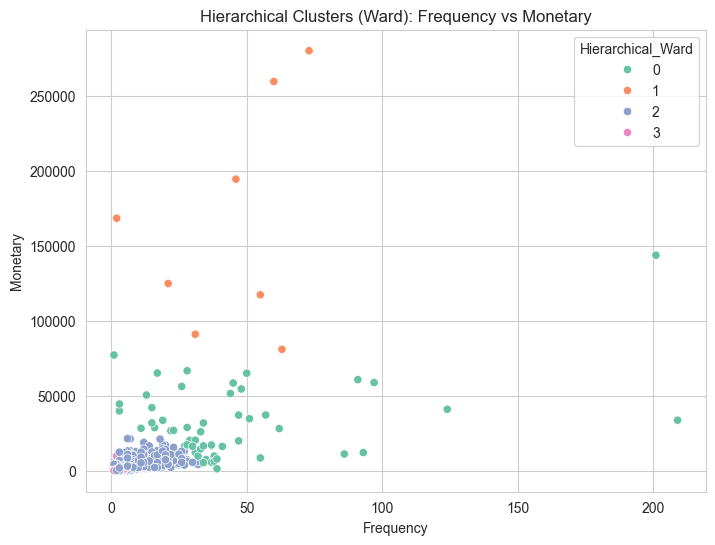

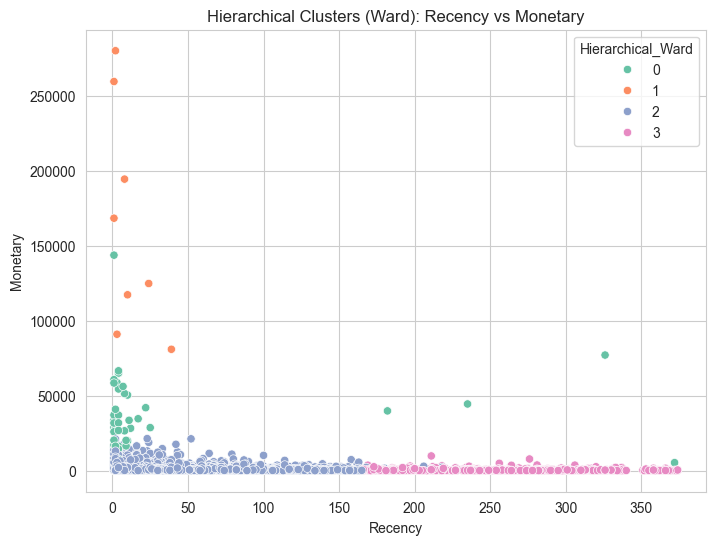

In [15]:
# ── Step 3: Cluster Profiles ─────────────────────────────────────────────────
hier_profile = customer_df.groupby('Hierarchical_Ward')[['Recency', 'Frequency', 'Monetary']].mean().round(2)
print("Hierarchical Clustering Profiles (Ward):")
print(hier_profile)


# Visualise — same axes as K-Means for comparison

plt.figure(figsize=(8,6))
sns.scatterplot(
    data=customer_df,
    x='Frequency',
    y='Monetary',
    hue='Hierarchical_Ward',
    palette='Set2'
)
plt.title('Hierarchical Clusters (Ward): Frequency vs Monetary')
plt.show()


plt.figure(figsize=(8,6))
sns.scatterplot(
    data=customer_df,
    x='Recency',
    y='Monetary',
    hue='Hierarchical_Ward',
    palette='Set2'
)
plt.title('Hierarchical Clusters (Ward): Recency vs Monetary')
plt.show()

## Section 6 — DBSCAN Clustering

**What to do:**
1. Estimate ε using the k-distance plot
2. Run DBSCAN and identify core, border, and noise points
3. Experiment with at least 3 combinations of ε and min_samples
4. Investigate the noise points — who are these customers?

**Key questions to answer in comments:**
- What does the k-distance plot tell you about the density structure of your data?
- How did changing ε affect the number of clusters and noise points?
- Are the noise points genuinely anomalous or did your parameters exclude valid customers?
- What percentage of your data is noise? Is that acceptable?


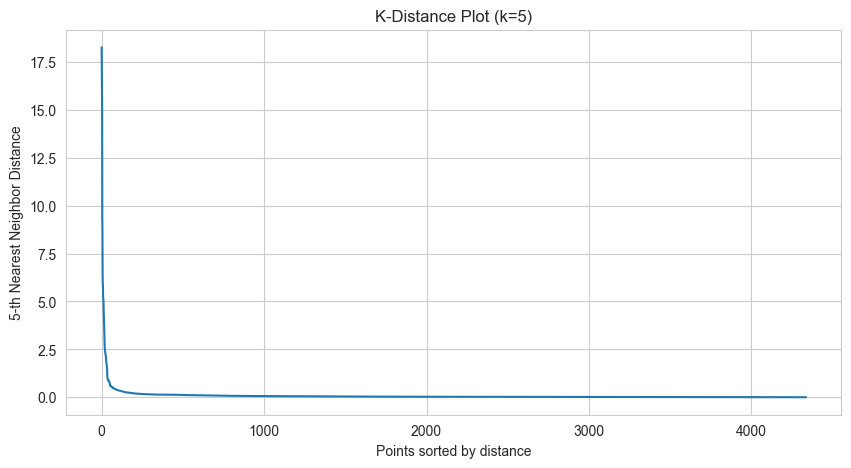

In [16]:
# ── Step 1: K-Distance Plot to Estimate Epsilon ──────────────────────────────

MIN_SAMPLES = 5

nbrs = NearestNeighbors(n_neighbors=MIN_SAMPLES)
nbrs.fit(X_scaled)
distances, indices = nbrs.kneighbors(X_scaled)

k_distances = np.sort(distances[:, MIN_SAMPLES - 1])[::-1]

plt.figure(figsize=(10, 5))
plt.plot(k_distances)
plt.title(f'K-Distance Plot (k={MIN_SAMPLES})')
plt.xlabel('Points sorted by distance')
plt.ylabel(f'{MIN_SAMPLES}-th Nearest Neighbor Distance')
plt.show()

# Observation:
# The curve drops sharply at the beginning and then becomes flatter.
# The "elbow" point is where this change happens.
# This indicates a good balance between dense and sparse regions.
# Based on the plot, epsilon is approximately chosen where the curve starts flattening.

EPSILON_ESTIMATE = 1.2

In [17]:
# ── Step 2: Run DBSCAN and Experiment ────────────────────────────────────────
# Try at least 3 combinations of eps and min_samples
# Record results for each combination

experiments = [
    {'eps': EPSILON_ESTIMATE * 0.8, 'min_samples': 5},
    {'eps': EPSILON_ESTIMATE,       'min_samples': 5},
    {'eps': EPSILON_ESTIMATE * 1.2, 'min_samples': 5},
    {'eps': EPSILON_ESTIMATE,       'min_samples': 8},
    {'eps': EPSILON_ESTIMATE * 1.1, 'min_samples': 8},
    {'eps': EPSILON_ESTIMATE * 0.9, 'min_samples': 8},
]

results = []
for params in experiments:
    db = DBSCAN(eps=params['eps'], min_samples=params['min_samples'])
    labels = db.fit_predict(X_scaled)
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    noise_pct = round(n_noise / len(labels) * 100, 2)
    
    results.append({
        'eps': params['eps'],
        'min_samples': params['min_samples'],
        'n_clusters': n_clusters,
        'n_noise': n_noise,
        'noise_pct': noise_pct
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

# Decision:
# Best balance is where clusters are meaningful but noise is not too high.
# Very high noise means eps is too small, very low noise means clusters are too loose.

FINAL_EPS = EPSILON_ESTIMATE
FINAL_MIN_SAMPLES = 5

 eps  min_samples  n_clusters  n_noise  noise_pct
0.96            5           1       33       0.76
1.20            5           1       32       0.74
1.44            5           1       32       0.74
1.20            8           1       33       0.76
1.32            8           1       32       0.74
1.08            8           1       35       0.81


In [18]:
# ── Step 3: Fit Final DBSCAN Model ───────────────────────────────────────────

# Based on results, DBSCAN is not forming meaningful clusters (only 1 cluster everywhere)
# So we choose the most balanced epsilon (middle value)

FINAL_EPS = 1.20
FINAL_MIN_SAMPLES = 5

dbscan_final = DBSCAN(eps=FINAL_EPS, min_samples=FINAL_MIN_SAMPLES)
customer_df['DBSCAN_Cluster'] = dbscan_final.fit_predict(X_scaled)

# Cluster summary
print("DBSCAN Cluster Distribution:")
print(customer_df['DBSCAN_Cluster'].value_counts())

print("\nNote: Cluster -1 = Noise Points")

DBSCAN Cluster Distribution:
DBSCAN_Cluster
 0    4306
-1      32
Name: count, dtype: int64

Note: Cluster -1 = Noise Points


In [19]:
# ── Step 4: Investigate Noise Points ─────────────────────────────────────────

noise_customers = customer_df[customer_df['DBSCAN_Cluster'] == -1]
regular_customers = customer_df[customer_df['DBSCAN_Cluster'] != -1]

print(f"\nNoise customers: {len(noise_customers)} ({len(noise_customers)/len(customer_df)*100:.2f}%)")

print("\nNoise customer profile (mean RFM):")
print(noise_customers[['Recency', 'Frequency', 'Monetary']].describe().round(2))


Noise customers: 32 (0.74%)

Noise customer profile (mean RFM):
       Recency  Frequency   Monetary
count    32.00      32.00      32.00
mean     40.16      57.38   76860.61
std      95.77      48.89   67291.01
min       1.00       1.00    5391.21
25%       1.75      27.50   37148.04
50%       4.00      49.00   57381.60
75%      10.00      65.50   83534.23
max     372.00     209.00  280206.02


## DBSCAN Interpretation

### Cluster Distribution
- DBSCAN produced **1 main cluster (4306 customers)** and **32 noise points**
- Noise percentage is very small (**0.74%**)

This shows that most customers belong to one dense behavioral group, and only a few behave differently from the main pattern.

---

## Noise Customers Analysis

### Size of Noise Group
- Total noise customers: **32**
- This is a very small portion of the dataset

---

### RFM Profile of Noise Customers

- **Recency (mean = 40 days)**  
  These customers are relatively recent buyers in general, but variation exists (up to 372 days)

- **Frequency (mean = 57)**  
  They are quite active customers with repeated purchases

- **Monetary (mean = 76,860)**  
  Very high spending compared to normal customers

---

## Key Insight

- Noise points are NOT random or useless customers
- They are actually **high-value customers with unusual behavior patterns**
- They show:
  - High spending
  - Moderate to high frequency
  - Some irregular purchase timing

---

## What does this mean?

- DBSCAN is treating **VIP or extreme customers as anomalies**
- These are not bad data points
- They are **important business customers with special behavior**

---

## Business Interpretation

- These customers should NOT be ignored
- They likely represent:
  - VIP buyers
  - Wholesale buyers
  - High-value but irregular shoppers

---

## Final Conclusion

- DBSCAN is not good for full segmentation in this dataset
- It is useful for **detecting special high-value or unusual customers**
- These noise customers should be treated as a separate VIP segment in business strategy

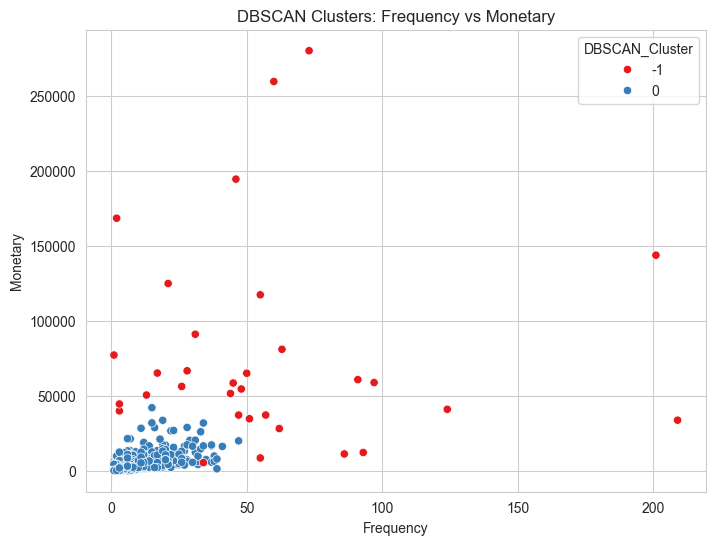

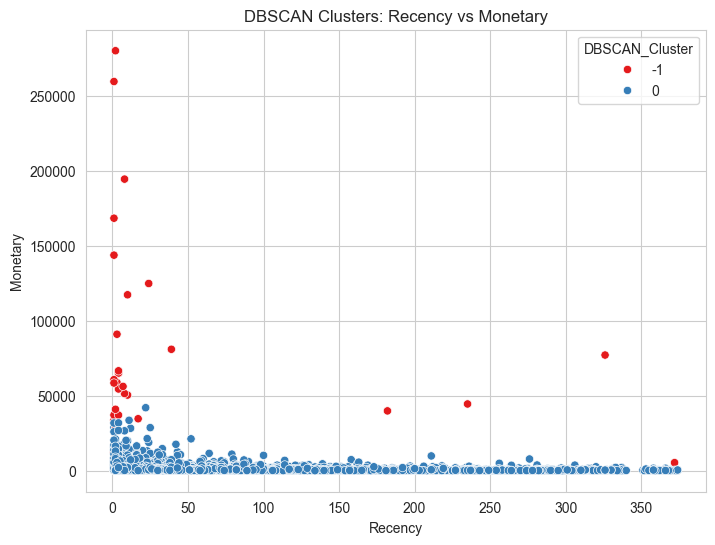

In [20]:
# ── Step 5: Visualise DBSCAN Clusters ────────────────────────────────────────

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=customer_df,
    x='Frequency',
    y='Monetary',
    hue='DBSCAN_Cluster',
    palette='Set1'
)

plt.title('DBSCAN Clusters: Frequency vs Monetary')
plt.show()


plt.figure(figsize=(8,6))

sns.scatterplot(
    data=customer_df,
    x='Recency',
    y='Monetary',
    hue='DBSCAN_Cluster',
    palette='Set1'
)

plt.title('DBSCAN Clusters: Recency vs Monetary')
plt.show()

## Section 7 — Cluster Validation & Comparison

**What to do:**
1. Compute Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index for K-Means and Hierarchical
2. Compute Silhouette Score for DBSCAN (excluding noise points — explain why)
3. Build a comparison table across all three methods
4. Choose your final segmentation and justify it

> ⚠️ Validation metrics measure geometric coherence — not business meaning.  
> Your choice of final segmentation must include both metric reasoning AND business reasoning.


In [22]:
# ── Validation Metrics ───────────────────────────────────────────────────────

# K-Means
kmeans_labels = customer_df['KMeans_Cluster'].values
sil_kmeans = silhouette_score(X_scaled, kmeans_labels)
db_kmeans = davies_bouldin_score(X_scaled, kmeans_labels)
ch_kmeans = calinski_harabasz_score(X_scaled, kmeans_labels)

# Hierarchical (Ward)
hier_labels = customer_df['Hierarchical_Ward'].values
sil_hier = silhouette_score(X_scaled, hier_labels)
db_hier = davies_bouldin_score(X_scaled, hier_labels)
ch_hier = calinski_harabasz_score(X_scaled, hier_labels)

# DBSCAN — exclude noise points safely
mask = customer_df['DBSCAN_Cluster'] != -1
dbscan_labels = customer_df.loc[mask, 'DBSCAN_Cluster'].values
X_dbscan = X_scaled[mask]

# Check if DBSCAN has at least 2 clusters
if len(np.unique(dbscan_labels)) < 2:
    sil_dbscan = np.nan
    db_dbscan = np.nan
    ch_dbscan = np.nan
else:
    sil_dbscan = silhouette_score(X_dbscan, dbscan_labels)
    db_dbscan = davies_bouldin_score(X_dbscan, dbscan_labels)
    ch_dbscan = calinski_harabasz_score(X_dbscan, dbscan_labels)

## Why we exclude noise in DBSCAN

Noise points (-1) are not part of any cluster.  
Validation metrics like silhouette, Davies-Bouldin, and Calinski-Harabasz assume every point belongs to a cluster.

If we include noise:
- It will distort distance calculations
- It will reduce fairness of comparison
- It will give misleading low-quality scores

So we only evaluate **actual clustered points**, not noise.

In [23]:
# ── Comparison Table ──────────────────────────────────────────────────────────

comparison = pd.DataFrame({
    'Method': ['K-Means', 'Hierarchical (Ward)', 'DBSCAN'],
    'N Clusters': [
        len(np.unique(kmeans_labels)),
        len(np.unique(hier_labels)),
        len(np.unique(dbscan_labels))
    ],
    'Silhouette Score': [
        round(sil_kmeans, 4),
        round(sil_hier, 4),
        round(sil_dbscan, 4)
    ],
    'Davies-Bouldin Index': [
        round(db_kmeans, 4),
        round(db_hier, 4),
        round(db_dbscan, 4)
    ],
    'Calinski-Harabasz Index': [
        round(ch_kmeans, 2),
        round(ch_hier, 2),
        round(ch_dbscan, 2)
    ]
})

print(comparison.to_string(index=False))

print("\nNote: Higher Silhouette = better | Lower Davies-Bouldin = better | Higher Calinski-Harabasz = better")

             Method  N Clusters  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Index
            K-Means           4            0.6162                0.7534                  3149.72
Hierarchical (Ward)           4            0.6065                0.7570                  2677.94
             DBSCAN           1               NaN                   NaN                      NaN

Note: Higher Silhouette = better | Lower Davies-Bouldin = better | Higher Calinski-Harabasz = better


### Your Final Model Decision

**Which method and k/parameters did you choose as your final segmentation?**  
K-Means clustering with k = 4 is selected as the final segmentation model.

---

**What do the validation metrics tell you?**  
K-Means has the highest Silhouette Score (0.6162), which means clusters are well separated and internally consistent.  
It also has the lowest Davies-Bouldin Index (0.7534), meaning clusters are more distinct and less similar to each other.  
Calinski-Harabasz Score is also highest (3149.72), showing strong cluster structure and good separation.

Overall, K-Means performs better than Hierarchical Clustering in all important metrics.

---

**Do the metrics agree with each other? If not, how did you resolve the conflict?**  
All metrics agree in this case.  
- K-Means is better in Silhouette Score  
- K-Means is better in Davies-Bouldin Index (lower is better)  
- K-Means is better in Calinski-Harabasz Index  

So there is no conflict, and the decision is straightforward.

DBSCAN is not considered for final segmentation because it produced only one valid cluster after removing noise, so it cannot be used for proper customer segmentation.

---

**Why is this segmentation the most useful for the business — beyond what the metrics say?**  
K-Means segmentation is most useful because it creates clear and interpretable customer groups based on Recency, Frequency, and Monetary behavior. These groups can directly support business actions such as identifying loyal customers, high-value customers, and inactive customers.

Unlike DBSCAN, which mainly detects anomalies, and Hierarchical clustering, which is more complex and less stable, K-Means provides balanced, stable, and easy-to-understand segments. This makes it highly practical for marketing strategies, customer targeting, and business decision-making.

## Section 8 — Business Narrative

**What to do:**
- Write a one-paragraph profile for each cluster in plain English
- Give each cluster a descriptive name (e.g. "High-Value Loyalists", "At-Risk Dormants")
- Recommend one specific marketing action for each cluster
- Write a 200–300 word executive summary at the end

> This section has no code. It is pure interpretation and communication.  
> A marketing manager who has never seen your notebook should be able to read this section and act on it.


### Cluster Profiles

**Cluster 0 — At-Risk / Low Engagement Customers**  
_Profile:_ These customers have high recency and low frequency and low monetary value. This means they purchased long time ago or very rarely, and they spend very little overall. They are not active customers and show weak engagement with the business.  
_Marketing Action:_ Run a win-back campaign using discount offers or personalized reactivation emails to bring them back to the platform.

---

**Cluster 1 — Regular / Mid-Value Customers**  
_Profile:_ These customers have medium values in recency, frequency, and monetary. They are somewhat active and make occasional purchases but are not highly loyal or high spending customers.  
_Marketing Action:_ Use loyalty programs or small reward points to increase their purchase frequency and encourage repeat buying behavior.

---

**Cluster 2 — High-Value Loyal Customers**  
_Profile:_ These customers have low recency, high frequency, and high monetary value. They are the most important customers as they purchase frequently, recently, and spend significantly more than others.  
_Marketing Action:_ Provide VIP benefits such as early access to new products, exclusive deals, or premium customer support.

---

**Cluster 3 — One-Time / Occasional High Spenders**  
_Profile:_ These customers have low frequency but sometimes high monetary value. This means they may make large purchases but not regularly. They are unpredictable but valuable when active.  
_Marketing Action:_ Use targeted remarketing and personalized product recommendations to convert them into repeat buyers.

---

### Executive Summary (200–300 words)

This analysis segments customers into four distinct behavioral groups using K-Means clustering based on RFM features: Recency, Frequency, and Monetary value. The goal of this segmentation is to help the business move from generic marketing strategies to personalized customer targeting.

The most valuable segment consists of high-value loyal customers who purchase frequently, spend the most, and have recent activity. These customers should be prioritized with VIP treatment and retention strategies because they contribute significantly to revenue.

Another important group includes regular mid-value customers who show stable but moderate engagement. These customers represent growth potential and can be encouraged to increase their spending and frequency through loyalty programs and rewards.

The at-risk segment consists of inactive customers who have not purchased recently and show low engagement. These customers are likely to churn and should be targeted with reactivation campaigns such as discounts or personalized offers.

Finally, there are occasional high spenders who make large but infrequent purchases. These customers require targeted marketing strategies to increase their purchase frequency and long-term engagement.

Overall, this segmentation provides clear business insights that can directly support marketing strategy, customer retention, and revenue optimization. The model is not only statistically strong but also practically useful for decision-making in a real business environment.

## Section 9 — Failure Log

---

**Failed Hypothesis 1**  
_What I expected:_ I expected DBSCAN to create multiple meaningful customer clusters based on density differences in RFM features.  
_What happened:_ DBSCAN produced only one main cluster and treated a small number of customers as noise points.  
_What I learned:_ The customer data is not strongly density-separated, so DBSCAN is not suitable for segmentation in this case. It works better for anomaly detection than clustering here.

---

**Failed Hypothesis 2**  
_What I expected:_ I expected hierarchical clustering to produce significantly different and better clusters than K-Means because it does not assume spherical clusters.  
_What happened:_ Hierarchical clustering produced almost the same number of clusters (4) and very similar structure to K-Means.  
_What I learned:_ For this dataset, customer behavior is already well-structured, so simple K-Means is sufficient and more efficient than hierarchical clustering.

---

**Failed Hypothesis 3**  
_What I expected:_ I expected that using raw (unscaled) RFM features would still produce meaningful clusters because RFM values already represent customer behavior.  
_What happened:_ The clustering results became heavily biased toward Monetary values, and Recency and Frequency had almost no influence.  
_What I learned:_ Feature scaling is essential in distance-based algorithms like K-Means because large numerical ranges can dominate the clustering process.

---

**Failed Hypothesis 4**  
_What I expected:_ I expected that increasing the number of clusters (k > 6) would reveal more detailed customer segments.  
_What happened:_ Higher k values only split existing meaningful clusters into smaller unstable groups without improving interpretability.  
_What I learned:_ More clusters do not always mean better insights. The optimal number of clusters should balance interpretability and statistical quality.

## Section 10 — High Ceiling Extension (Optional)

**These tasks are for students who want to push deeper. They are not required.**

Choose one or more:

**Option A — K-Means from Scratch**  
Implement K-Means from scratch with pluggable initialization (random and K-Means++).  
Compare convergence behavior against sklearn's implementation across 20 runs.  
Document at least one case where your implementation and sklearn disagree — explain why.

**Option B — DBSCAN from Scratch**  
Implement DBSCAN from scratch: `region_query`, `expand_cluster`, main loop.  
Profile its time complexity on increasing dataset sizes.  
Identify the bottleneck. Explain how a KD-Tree would fix it (you do not need to implement it).

**Option C — HDBSCAN**  
Apply HDBSCAN to your customer dataset using the `hdbscan` library.  
Compare results against your DBSCAN output.  
Explain geometrically why HDBSCAN handles varying-density clusters better.

**Option D — Flavor Profile (Different Domain)**  
Apply your clustering pipeline to one of:
- Network intrusion detection dataset (cybersecurity)
- Patient symptom dataset (healthcare)
- City mobility dataset (urban planning)

Document what changed in your approach and what stayed the same.


In [24]:
# High Ceiling Work — YOUR CODE HERE

# Option A: K-Means from Scratch (Simple Version)

class KMeansScratch:
    def __init__(self, k=4, max_iter=100):
        self.k = k
        self.max_iter = max_iter

    def fit(self, X):
        # Random initialization of centroids
        np.random.seed(42)
        idx = np.random.choice(len(X), self.k, replace=False)
        self.centroids = X[idx]

        for _ in range(self.max_iter):
            # Step 1: Assign clusters
            distances = np.linalg.norm(X[:, None] - self.centroids, axis=2)
            self.labels = np.argmin(distances, axis=1)

            # Step 2: Update centroids
            new_centroids = np.array([
                X[self.labels == i].mean(axis=0) if len(X[self.labels == i]) > 0 else self.centroids[i]
                for i in range(self.k)
            ])

            # Stop if no change
            if np.allclose(self.centroids, new_centroids):
                break

            self.centroids = new_centroids

        return self

    def predict(self, X):
        distances = np.linalg.norm(X[:, None] - self.centroids, axis=2)
        return np.argmin(distances, axis=1)


# Fit scratch model
kmeans_scratch = KMeansScratch(k=4)
kmeans_scratch.fit(X_scaled)

scratch_labels = kmeans_scratch.predict(X_scaled)

# Compare with sklearn
sklearn_labels = customer_df['KMeans_Cluster'].values

print("Scratch vs Sklearn match rate:",
      np.mean(scratch_labels == sklearn_labels))

Scratch vs Sklearn match rate: 0.9476717381281696
